# Tema 06 · Modelos pequeños e IA local
## ¿Cuánto ahorra INT8 al clasificar solicitudes universitarias en español?

**Curso** · Inteligencia Artificial  
**Integrantes** · Integrante solicitante (nombre por completar), Juan Esteban Gallego y Luis Esteban Ospina  
**Grupo, inicio oficial y turno de exposición** · Por confirmar según el registro del curso

### A. Identificación y elección
Un sistema universitario puede usar un clasificador local para dirigir consultas cortas a becas, horarios o certificados. Medir una tarea acotada permite decidir si merece la pena comprimir el modelo aun cuando el equipo disponga de una CPU convencional. El clasificador aprende de textos etiquetados. La representación TF–IDF transforma fragmentos de caracteres en señales numéricas y la decisión es elegir la clase con mayor puntuación. Podría ser el primer componente de un agente de atención. En el estudio se evalúa únicamente la clasificación.

Rotación propuesta, pendiente de adopción y registro por los integrantes.

| Semana | Fuentes | Diseño y ejecución | Análisis y comunicación |
|---|---|---|---|
| 1 | Integrante solicitante | Juan Esteban Gallego | Luis Esteban Ospina |
| 2 | Luis Esteban Ospina | Integrante solicitante | Juan Esteban Gallego |
| 3 | Juan Esteban Gallego | Luis Esteban Ospina | Integrante solicitante |
| 4 | Los tres sustentan | Los tres ensayan | Los tres participan |

### B. Pregunta, hipótesis y alcance
**Pregunta.** En 27 solicitudes sintéticas reservadas en español, ¿puede INT8 reducir el costo de almacenamiento de los pesos de un clasificador TF–IDF y regresión logística ejecutado en CPU, manteniendo la exactitud de FP32 dentro de un caso?

**Hipótesis operativa.** La configuración INT8 reducirá al menos 70 % la memoria de los arreglos paramétricos, con una pérdida de exactitud de como máximo un acierto de 27 (3,70 puntos porcentuales). Fallará este criterio si el ahorro queda por debajo del 70 % o si B pierde 2 aciertos o más. Se miden el tamaño serializado y la latencia como resultados secundarios sin umbral de aceptación. El criterio es descriptivo para este conjunto.

**Objetivo general.** Medir el intercambio entre calidad y recursos de dos precisiones del mismo modelo local.  
**Objetivos específicos.** Construir y separar ejemplos de entrenamiento, piloto y prueba. Comparar calidad, tamaño y tiempo bajo un protocolo pareado. Examinar qué entradas provocan errores y qué cambiaría en un entorno real.

**Alcance.** Consultas sintéticas de una sola intención principal, clasificación cerrada de tres clases y predicción de un texto por llamada. Quedan fuera los LLM generativos, la atención real, la detección de clases desconocidas y las comparaciones con un servicio remoto. Se usan CPU, Python y paquetes de código abierto sin API. Ante falta de acceso al entorno original, se puede reinstalar en otra CPU Linux y comparar la exactitud, registrando los nuevos tiempos por separado. Los CSV y salidas guardadas permiten revisar la ejecución original sin reinstalar.

### C. Revisión de fuentes y marco conceptual

**Estrategia.** El 24 de noviembre de 2026 (hora de Colombia) se realizó una búsqueda dirigida en repositorios de autores y documentación oficial. Las consultas temáticas fueron `Qwen3 Technical Report 2025 quantization`, `SmolLM3 2025 training multilingual`, `scikit-learn character n-grams TF-IDF`, `gemmlowp affine quantization` y `Hinton knowledge distillation 2015`. Se priorizaron fuentes primarias con descripción de la técnica, fecha o versión identificable y límites claros. El proxy bloqueó la consulta directa a arXiv. Para Qwen3 se usó el repositorio oficial y para destilación se corroboró la referencia del trabajo fundacional con el [ejemplo oficial de Keras](https://github.com/keras-team/keras-io/blob/master/examples/vision/knowledge_distillation.py). La consulta directa del preprint quedó pendiente.

| ID | Referencia | Año / versión | Tipo | Aporte y límite |
|---|---|---|---|---|
| F1 | Qwen Team. [Qwen3](https://github.com/QwenLM/Qwen3#readme) | Lanzamiento 2025 | Documentación primaria de autores, sin arbitraje de la documentación | Publica una familia de tamaños y rutas para desplegar modelos cuantizados. Las variantes difieren también en arquitectura y presupuesto, por lo que tamaño por sí solo no explica su rendimiento. |
| F2 | Hugging Face TB. [SmolLM3: smol, multilingual, long-context reasoner](https://github.com/huggingface/blog/blob/main/smollm3.md) | Lanzamiento 2025, SmolLM3 3B | Documentación primaria de autores, sin arbitraje de la documentación | Modelo de 3 mil millones de parámetros con soporte declarado para español y publicación de configuraciones. Sus comparaciones reportadas corresponden a sus benchmarks, no a clasificación universitaria. |
| F3 | Desarrolladores de scikit-learn. [Feature extraction](https://github.com/scikit-learn/scikit-learn/blob/1.8.0/doc/modules/feature_extraction.rst) | 1.8.0 | Documentación primaria de implementación | Explica las representaciones dispersas, TF–IDF y n-gramas de caracteres. Describe cómo representar el texto, sin garantizar calidad con un corpus pequeño. |
| F4 | Equipo de gemmlowp. [Building a quantization paradigm from first principles](https://github.com/google/gemmlowp/blob/master/doc/quantization.md) | Documento técnico del repositorio | Documentación primaria de implementación | Deriva la cuantización afín y la relación entre escala, entero y punto cero. El núcleo de cálculo descrito difiere del producto mixto de este estudio. |
| F5 | Hinton, G., Vinyals, O. y Dean, J. [Distilling the Knowledge in a Neural Network](https://arxiv.org/abs/1503.02531) | 2015, arXiv v1 | Trabajo fundacional, preprint | Propone transferir información de un sistema docente a un estudiante mediante salidas suaves. La destilación requiere entrenamiento y responde a una pregunta distinta a la conversión numérica de pesos. |

**Síntesis crítica.** Qwen y Hugging Face muestran dos estrategias complementarias: ofrecer tamaños distintos o diseñar y entrenar un modelo compacto. Sus cifras se refieren a arquitecturas y bancos de evaluación propios. Aquí se fija la representación y se cambia únicamente el almacenamiento de los pesos, una comparación más cercana a la formulación de gemmlowp. La documentación de scikit-learn sustenta la representación de texto. La destilación sería otra intervención y requeriría un profesor y un estudiante.

**Esquema propio**

```text
54 textos etiquetados → ajustar TF–IDF y regresión logística
                                       ↓
texto reservado → TF–IDF fijo → pesos FP32 o INT8 → tres puntuaciones → argmáx
                                                                           ↓
                                                comparar con etiqueta de referencia
```

Los **parámetros** son coeficientes y sesgos aprendidos. En A se conservan en FP32. Para B, cada clase tiene una escala igual a su peso absoluto máximo dividido entre 127. Cada peso se divide por esa escala, se redondea y se almacena en un entero con signo. Se multiplica TF–IDF por esos pesos, se reescala el resultado y se suma el mismo sesgo. SciPy usa cálculo en punto flotante con la entrada dispersa, por lo que almacenar INT8 no garantiza una ruta rápida de cómputo entero. **Memoria** es espacio ocupado durante ejecución. **Tamaño serializado** es el número de bytes de una representación persistible. **Latencia** es el tiempo de transformación y predicción para una solicitud. La inferencia puede mantenerse dentro del equipo, aunque la privacidad también depende de quién accede al dispositivo y de qué consultas se conservan en registros.

### D. Protocolo experimental

| Elemento | Decisión |
|---|---|
| Referencia A | Regresión logística con pesos FP32. |
| Alternativa B | Los mismos pesos en INT8 simétrico por clase. Escalas y sesgos FP32. |
| Factor que cambia | Precisión de almacenamiento de los pesos y operaciones asociadas al reescalado. |
| Controles | Mismo entrenamiento, vectorizador, etiquetas, texto, máquina, lote unitario y una ejecución secuencial. |
| Datos | 54 ejemplos sintéticos de entrenamiento (18 por clase), 6 de piloto y 27 finales (9 por clase). La prueba tiene 9 directos, 9 indirectos y 9 con distractor, equilibrados por clase. |
| Separación | Tres listas disjuntas con comprobación de duplicados exactos. El vectorizador y la regresión se ajustan únicamente con los 54 ejemplos de entrenamiento. |
| Etiqueta de referencia | La acción principal define el destino. Solicitar ayuda económica es BECAS, ubicar o cambiar una sesión es HORARIOS, pedir un documento probatorio es CERTIFICADOS. Cuando se menciona un segundo trámite, se etiqueta la petición explícita que aún se debe atender. Ejemplo F25 pide descargar una constancia aunque la finalidad sea renovar la beca. |
| Métrica principal | Exactitud = aciertos / 27. Las 31 repeticiones de latencia conservan una única observación de calidad por caso. |
| Secundarias | F1 macro (media del F1 de las tres clases), matriz de confusión, acierto por dificultad, mediana y cuartiles de latencia, bytes de arreglos, bytes del archivo de parámetros y máximo de asignaciones temporales rastreadas por llamada. |
| Repetición y tiempo | 11 repeticiones por configuración y caso en piloto, 31 en evaluación. Ocho llamadas de calentamiento por condición al inicio de cada fase. Se alterna el orden A/B según caso y repetición. El código valida que las predicciones coincidan entre repeticiones. |
| Configuración | TF–IDF de caracteres de longitud 2 a 5, normalización L2 y TF sublineal. Regresión logística multiclase con L-BFGS, C=4 y hasta 1000 iteraciones. |
| Exclusiones | No se retiran casos por dificultad ni error de predicción. Si una llamada genera una excepción o las predicciones dejan de ser deterministas se registra el incidente y se detiene la corrida para investigar antes de publicar una nueva versión. |
| Recursos | CPU Linux, Python 3.12 y un hilo configurado para BLAS/OpenMP. Se registra hardware y versiones en la salida ejecutada. No se compraron recursos ni se usó una API de inferencia. |

**Procedimiento.** Ajustar el vectorizador y el clasificador con el conjunto de entrenamiento. Construir A y B desde los mismos coeficientes. Calentar por condición y presentar las mismas solicitudes. Cronometrar vectorización y predicción sin medir escritura de archivos ni rastreo de memoria. Guardar etiquetas, puntuaciones y tiempos. Medir memoria en una pasada aparte. Comparar ocurrencias de error por pares.

**Validez.** El conjunto sintético y pequeño puede favorecer expresiones parecidas a las del entrenamiento. Se incluyen paráfrasis y distractores y se limita la conclusión a estos casos. La temporización depende del entorno y del orden. Las condiciones se alternan en el mismo proceso y se informa la dispersión. Los autores del corpus también fijan las etiquetas. Un segundo anotador ciego ayudaría a evaluar casos difusos.

In [1]:
import os
from datetime import datetime
from zoneinfo import ZoneInfo
import platform

os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ.setdefault('MPLCONFIGDIR', '/tmp/ia-tema06-matplotlib')
os.environ.setdefault('XDG_CACHE_HOME', '/tmp/ia-tema06-cache')

train = {
'BECAS':[
'Quiero solicitar apoyo económico para pagar la matrícula','Cuáles requisitos pide la beca de excelencia','Cómo renuevo mi subsidio de sostenimiento','Necesito información sobre auxilios de alimentación','Dónde envío mis documentos para la beca','La beca cubre todo el semestre','Puedo postular al fondo de emergencia','No recibí el desembolso de mi subsidio','Qué promedio necesito para conservar la beca','Busco financiación para estudiantes de bajos ingresos','Está abierta la convocatoria de becas','Cómo demuestro mis ingresos para el auxilio','Cuándo publican beneficiarios del apoyo económico','Mi beca quedó suspendida por error','Necesito ayuda financiera para continuar estudiando','Me interesa el subsidio de transporte','Puedo pedir un descuento por situación económica','Dónde consulto el estado de mi postulación al auxilio'],
'HORARIOS':[
'En qué salón es la clase de cálculo','A qué hora empieza el laboratorio de física','Necesito cambiar de grupo por cruce de horarios','Qué días ofrecen fundamentos de programación','Dónde veo el horario del próximo semestre','La clase se movió al bloque B','Hay otro grupo de álgebra en la tarde','Me coincide inglés con estadística','Cuál es el aula de la clase del viernes','Quiero mover mi clase a la mañana','El profesor cambió la hora del curso','Mi horario muestra dos materias a la vez','Cuándo se reúne el grupo de investigación','Dónde puedo consultar los salones asignados','Qué franjas quedan disponibles para química','Puedo pasar a la comisión nocturna','Cuál es el nuevo horario de la tutoría','No aparece el aula en el calendario de clases'],
'CERTIFICADOS':[
'Quiero solicitar un certificado de estudios','Necesito una constancia de matrícula para mi trabajo','Cómo descargo el historial de notas','Dónde pido un certificado de calificaciones','Me solicitan una constancia de que estoy matriculado','Cómo obtengo un duplicado del diploma','El certificado académico lleva firma digital','Quiero una copia oficial del acta de grado','Puedo pedir el certificado en inglés','El historial académico tiene una nota incorrecta','Necesito comprobar que soy estudiante activo','Cuánto tarda la expedición de la constancia','Dónde pago el certificado de notas','Cómo solicito un récord académico sellado','Puedo enviar mi constancia por correo','Requiero certificación de materias cursadas','Quiero el documento oficial de egresado','Cómo valido la autenticidad del diploma']}
pilot = [
('BECAS','Qué papeles pide el subsidio de movilidad'),
('CERTIFICADOS','Me exigen un comprobante oficial de estudios'),
('HORARIOS','En qué aula nos toca el martes'),
('HORARIOS','Quisiera un grupo por la noche'),
('BECAS','A quién aviso si no llegó el apoyo'),
('CERTIFICADOS','Solicito copia firmada de mi acta')]
final = [
('CERTIFICADOS','Para mi EPS necesito acreditar que sigo inscrita','directo'),
('BECAS','Dónde registro mi solicitud de subsidio de transporte','directo'),
('HORARIOS','¿En qué bloque dan la clase de geometría?','directo'),
('CERTIFICADOS','Emiten un certificado con todas mis notas y créditos','directo'),
('HORARIOS','El miércoles puedo asistir al laboratorio solo por la tarde','directo'),
('BECAS','Cuál es el plazo para renovar la beca de excelencia','directo'),
('CERTIFICADOS','Cómo pido otra copia de mi acta de grado','directo'),
('BECAS','No me consignaron el auxilio de alimentación','directo'),
('HORARIOS','Necesito ver si las materias se cruzan los jueves','directo'),
('CERTIFICADOS','Quiero el papel timbrado que dice que sigo vinculado','indirecto'),
('BECAS','Me quedé sin cómo costear el semestre, ¿hay ayuda?','indirecto'),
('HORARIOS','¿A qué edificio tengo que ir después del descanso?','indirecto'),
('CERTIFICADOS','El consulado quiere prueba oficial de mi trayectoria académica','indirecto'),
('HORARIOS','Me sirven las sesiones que arrancan luego de las seis','indirecto'),
('BECAS','¿La universidad puede cubrirme los pasajes?','indirecto'),
('CERTIFICADOS','¿Me dan algo firmado para probar que terminé la carrera?','indirecto'),
('BECAS','Necesito que me alivien el valor del recibo, perdí el empleo','indirecto'),
('HORARIOS','En el portal dos cursos quedaron montados a la misma hora','indirecto'),
('CERTIFICADOS','Ya tengo beca, necesito únicamente el certificado de estudio','distractor'),
('BECAS','Tengo mi constancia firmada, ¿cómo pido el auxilio de sostenimiento?','distractor'),
('HORARIOS','La beca ya está resuelta, solo quiero saber en qué salón es la clase','distractor'),
('CERTIFICADOS','El horario aparece bien, lo que requiero es mi historial de calificaciones','distractor'),
('HORARIOS','Tengo el certificado de matrícula, solo quiero cambiar la franja de química','distractor'),
('BECAS','Ya sé la hora de clase, díganme si me ayudan a pagar el semestre','distractor'),
('CERTIFICADOS','Para renovar la beca me exigen una constancia sellada, ¿cómo la descargo?','distractor'),
('BECAS','Tengo el historial de notas, quiero saber cómo financiar la matrícula','distractor'),
('HORARIOS','Ya entregué los papeles del subsidio, ¿cuándo se reúne mi grupo?','distractor')]

import csv
import io
import tracemalloc
from collections import Counter
from pathlib import Path
from time import perf_counter_ns
from zipfile import ZIP_STORED, ZipFile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score

labels = sorted(train)
assert len({t for rows in train.values() for t in rows} | {t for _, t in pilot} |
           {t for _, t, _ in final}) == 87
vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2, 5),
                             sublinear_tf=True, dtype=np.float32)
x_train = vectorizer.fit_transform([t for label in labels for t in train[label]])
classifier = LogisticRegression(C=4, solver="lbfgs", max_iter=1000)
classifier.fit(x_train, [label for label in labels for _ in train[label]])
assert classifier.classes_.tolist() == labels
weights = classifier.coef_.T.astype(np.float32)
bias = classifier.intercept_.astype(np.float32)
scale = np.max(np.abs(weights), axis=0) / np.float32(127)
assert np.all(scale > 0)
models = {
    "A": {"pesos": weights, "sesgo": bias.copy()},
    "B": {"pesos": np.rint(weights / scale).clip(-127, 127).astype(np.int8),
          "escala": scale, "sesgo": bias.copy()},
}

def predict(text, model):
    x = vectorizer.transform([text])
    scores = x @ model["pesos"]
    if "escala" in model:
        scores *= model["escala"]
    scores += model["sesgo"]
    return labels[int(scores.argmax())], scores.ravel().tolist()

def stored_bytes(model):
    output = io.BytesIO()
    with ZipFile(output, "w", ZIP_STORED) as archive:
        for key, array in model.items():
            data = io.BytesIO()
            np.save(data, array, allow_pickle=False)
            archive.writestr(key + ".npy", data.getvalue())
    return len(output.getvalue())

def traced_peak(model, cases):
    traces = []
    for _, text, _ in cases:
        tracemalloc.start()
        predict(text, model)
        traces.append(tracemalloc.get_traced_memory()[1])
        tracemalloc.stop()
    return max(traces)

def evaluate(cases, prefix, repeats):
    for model in models.values():
        for _, text, _ in cases[:1]:
            for _ in range(8):
                predict(text, model)
    records = []
    for index, (gold, text, difficulty) in enumerate(cases, 1):
        for repeat in range(1, repeats + 1):
            order = ("A", "B") if (index + repeat) % 2 == 0 else ("B", "A")
            for condition in order:
                start = perf_counter_ns()
                result, scores = predict(text, models[condition])
                elapsed = (perf_counter_ns() - start) / 1_000
                records.append(dict(caso=f"{prefix}{index:02}", dificultad=difficulty,
                                    condicion=condition, repeticion=repeat,
                                    posicion=order.index(condition) + 1,
                                    entrada=text, referencia=gold, salida=result,
                                    acierto=int(gold == result), latencia_us=elapsed,
                                    logit_becas=scores[0], logit_certificados=scores[1],
                                    logit_horarios=scores[2]))
    return records

def summarize(records, condition):
    rows = [r for r in records if r["condicion"] == condition]
    first = [r for r in rows if r["repeticion"] == 1]
    by_id = {r["caso"]: r["salida"] for r in first}
    assert all(by_id[r["caso"]] == r["salida"] for r in rows)
    gold = [r["referencia"] for r in first]
    pred = [r["salida"] for r in first]
    return dict(aciertos=sum(r["acierto"] for r in first), n=len(first),
                f1=f1_score(gold, pred, labels=labels, average="macro"),
                tiempos=np.quantile([r["latencia_us"] for r in rows], [.25,.5,.75]),
                matriz=confusion_matrix(gold, pred, labels=labels),
                grupos={d: (sum(r["acierto"] for r in first if r["dificultad"] == d),
                            sum(r["dificultad"] == d for r in first))
                        for d in sorted({r["dificultad"] for r in first})})

def write_csv(records, name):
    with Path(name).open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows(records)

### E. Piloto, ajustes y bitácora

Se comprobaron seis solicitudes distintas de las de entrenamiento y prueba, dos por clase. Se verificó que ambas condiciones pudieran producir una de las tres etiquetas y conservar las puntuaciones y los tiempos. Ambas acertaron 6 de 6. Se conservaron el modelo, la cuantización y la regla de etiquetado. El piloto respaldó pasar a una evaluación con más casos, 31 repeticiones de tiempo y análisis por nivel de dificultad, como se definió antes de calcular las métricas finales.

| Fase ejecutada | Responsable registrado | Actividad y evidencia | Decisión |
|---|---|---|---|
| Diseño | Codex, por encargo del solicitante | Corpus sintético, revisión documental y protocolo en A–D | Tres clases con igual representación. |
| Piloto · 24 nov 2026 | Codex | 6 casos; tabla y CSV de piloto | Mantener las configuraciones y reservar los casos finales. |
| Evaluación · 24 nov 2026 | Codex | 27 casos, tabla, figura y registro de F | Reportar los errores compartidos y distinguir las métricas de memoria. |
| Preparación de exposición | Codex | Presentación y guía de sustentación | Proponer intervenciones y usar el registro como demostración. |

**Protocolo fijado** el 24 de noviembre de 2026 tras ejecutar el piloto y antes de la primera corrida final. No se retocaron las clases, hiperparámetros ni criterios de acierto después de observar los resultados finales. Las semanas del curso son hitos del enunciado. La tabla registra la ejecución disponible y queda abierta a los aportes verificables del grupo.

In [2]:
pilot_records = evaluate([(gold, text, 'piloto') for gold, text in pilot], 'P', 11)
for i, (gold, text) in enumerate(pilot, 1):
    predictions = [row for row in pilot_records
                   if row['caso'] == f'P{i:02}' and row['repeticion'] == 1]
    print(f'P{i:02} · {text} · {gold} · ' +
          ', '.join(f"{row['condicion']}={row['salida']}" for row in sorted(
              predictions, key=lambda row: row['condicion'])))
for condition in models:
    result = summarize(pilot_records, condition)
    print(f"{condition}: {result['aciertos']}/{result['n']}; F1 macro {result['f1']:.3f}")

P01 · Qué papeles pide el subsidio de movilidad · BECAS · A=BECAS, B=BECAS
P02 · Me exigen un comprobante oficial de estudios · CERTIFICADOS · A=CERTIFICADOS, B=CERTIFICADOS
P03 · En qué aula nos toca el martes · HORARIOS · A=HORARIOS, B=HORARIOS
P04 · Quisiera un grupo por la noche · HORARIOS · A=HORARIOS, B=HORARIOS
P05 · A quién aviso si no llegó el apoyo · BECAS · A=BECAS, B=BECAS
P06 · Solicito copia firmada de mi acta · CERTIFICADOS · A=CERTIFICADOS, B=CERTIFICADOS
A: 6/6; F1 macro 1.000
B: 6/6; F1 macro 1.000


### F. Implementación, evidencias y resultados

Para reproducir desde la carpeta de la entrega, instale las versiones por medio de `python -m pip install -r requirements.txt`, abra este cuaderno con Jupyter y seleccione **Restart Kernel and Run All Cells**. La inferencia, el análisis y la demostración usan datos incluidos en el cuaderno y funcionan sin conexión después de instalar las dependencias.

Se incluyen [evidencias del piloto](evidencias/piloto.csv), [evidencias finales](evidencias/evaluacion_final.csv), [resumen con hardware y versiones](evidencias/resumen.json) y [figura](evidencias/resultados.png). Cada fila de los CSV conserva el texto, referencia, predicción, los tres logits en el orden de las etiquetas, repetición, posición, acierto y microsegundos. Los CSV preservan la corrida de entrega. Una nueva ejecución recalcula métricas y puede producir tiempos distintos.

In [3]:
import json
from IPython.display import Markdown, display

records = evaluate(final, 'F', 31)
assert len(records) == 27 * 2 * 31
assert len(pilot_records) == 6 * 2 * 11
summary = {}
for condition, model in models.items():
    result = summarize(records, condition)
    summary[condition] = {
        **result, 'tiempos': result['tiempos'].tolist(), 'matriz': result['matriz'].tolist(),
        'parametros_B': sum(array.nbytes for array in model.values()),
        'archivo_B': stored_bytes(model), 'traza_pico_B': traced_peak(model, final),
    }

cpuinfo = Path('/proc/cpuinfo')
cpu = next((line.partition(':')[2].strip() for line in cpuinfo.read_text().splitlines()
            if line.startswith('model name')), platform.machine()) if cpuinfo.exists() else platform.machine()
metadata = {
    'fecha_colombia': datetime.now(ZoneInfo('America/Bogota')).isoformat(timespec='seconds'),
    'cpu': cpu, 'so': platform.system(), 'arquitectura': platform.machine(),
    'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__,
    'scikit_learn': sklearn.__version__, 'matplotlib': matplotlib.__version__,
    'variables_blas_openmp': 1, 'n_terminos': len(vectorizer.vocabulary_),
    'n_pesos': weights.size, 'n_sesgos': bias.size, 'exclusiones': 0,
    'desacuerdos_AB': sum(a != b for a,b in zip(
        [r['salida'] for r in records if r['condicion'] == 'A' and r['repeticion'] == 1],
        [r['salida'] for r in records if r['condicion'] == 'B' and r['repeticion'] == 1])),
}
saved = {'entorno': metadata, 'resultados': summary, 'etiquetas': labels}
print(f"{cpu} · {metadata['so']} {metadata['arquitectura']} · {metadata['fecha_colombia']}")
print('Versiones:', *(f'{p} {metadata[p]}' for p in
      ('python','numpy','scipy','scikit_learn','matplotlib')))
print(f"{weights.size:,} pesos y {bias.size} sesgos; {metadata['desacuerdos_AB']} desacuerdos A/B")
table = ['| Condición | Aciertos / casos | F1 macro | Latencia mediana [Q1–Q3], µs | Arreglos, B | Archivo, B | Pico trazado, B |',
         '|---|---:|---:|---:|---:|---:|---:|']
for condition, result in summary.items():
    q1, med, q3 = result['tiempos']
    table.append(f"| {condition} | {result['aciertos']}/{result['n']} "
                 f"({result['aciertos']/result['n']:.1%}) | {result['f1']:.3f} | "
                 f"{med:.1f} [{q1:.1f}–{q3:.1f}] | {result['parametros_B']:,} | "
                 f"{result['archivo_B']:,} | {result['traza_pico_B']:,} |")
display(Markdown(chr(10).join(table)))
print('Matriz de confusión de A y B (filas: referencia; columnas: predicción):')
print(labels)
for condition, result in summary.items():
    print(condition, np.array(result['matriz']), result['grupos'], sep=chr(10))

AMD EPYC 9V74 80-Core Processor · Linux x86_64 · 2026-11-24T19:22:38-05:00
Versiones: python 3.12.14 numpy 2.3.5 scipy 1.17.0 scikit_learn 1.8.0 matplotlib 3.10.8
11,007 pesos y 3 sesgos; 0 desacuerdos A/B


| Condición | Aciertos / casos | F1 macro | Latencia mediana [Q1–Q3], µs | Arreglos, B | Archivo, B | Pico trazado, B |
|---|---:|---:|---:|---:|---:|---:|
| A | 20/27 (74.1%) | 0.737 | 224.4 [205.8–253.3] | 44,040 | 44,506 | 48,454 |
| B | 20/27 (74.1%) | 0.737 | 227.0 [210.1–263.3] | 11,031 | 11,721 | 59,219 |

Matriz de confusión de A y B (filas: referencia; columnas: predicción):
['BECAS', 'CERTIFICADOS', 'HORARIOS']
A
[[6 1 2]
 [1 8 0]
 [1 2 6]]
{'directo': (8, 9), 'distractor': (5, 9), 'indirecto': (7, 9)}
B
[[6 1 2]
 [1 8 0]
 [1 2 6]]
{'directo': (8, 9), 'distractor': (5, 9), 'indirecto': (7, 9)}


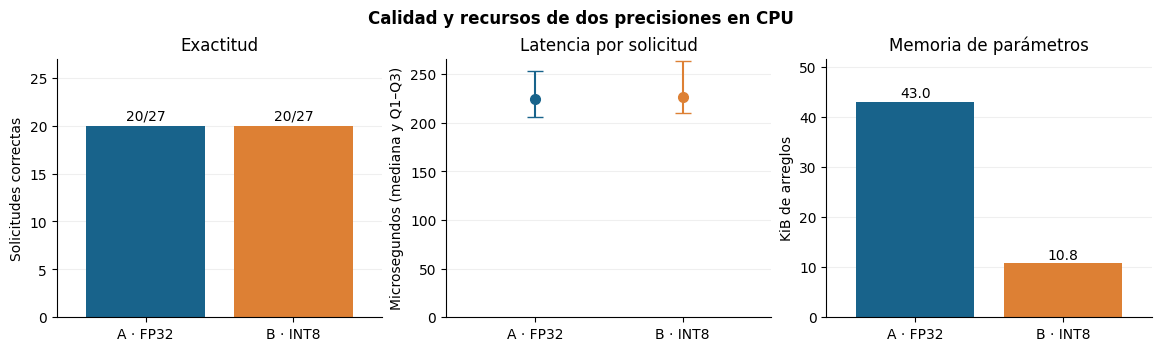

In [4]:
colors = ['#18638b', '#dd8034']
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4), layout='constrained')
fig.suptitle('Calidad y recursos de dos precisiones en CPU', fontweight='bold')
for i, (condition, result) in enumerate(summary.items()):
    x = result['aciertos']
    axes[0].bar(i, x, color=colors[i])
    axes[0].text(i, x + .6, f'{x}/27', ha='center')
    q1, med, q3 = result['tiempos']
    axes[1].errorbar(i, med, yerr=[[med-q1],[q3-med]], fmt='o',
                     color=colors[i], capsize=6, ms=7)
    size = result['parametros_B'] / 1024
    axes[2].bar(i, size, color=colors[i])
    axes[2].text(i, size + .8, f'{size:.1f}', ha='center')
for ax, title, ylabel in zip(axes, ['Exactitud','Latencia por solicitud','Memoria de parámetros'],
                              ['Solicitudes correctas', 'Microsegundos (mediana y Q1–Q3)', 'KiB de arreglos']):
    ax.set(title=title, ylabel=ylabel, xticks=[0,1], xticklabels=['A · FP32','B · INT8'], xlim=(-.6,1.6))
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
axes[0].set_ylim(0, 27)
axes[1].set_ylim(bottom=0)
axes[2].set_ylim(0, max(r['parametros_B'] for r in summary.values()) / 1024 * 1.2)
if os.environ.get('IA_TEMA06_EXPORT'):
    out = Path(os.environ['IA_TEMA06_EXPORT'])
    out.mkdir(parents=True, exist_ok=True)
    write_csv(pilot_records, out / 'piloto.csv')
    write_csv(records, out / 'evaluacion_final.csv')
    (out / 'resumen.json').write_text(json.dumps(saved, ensure_ascii=False, indent=2), encoding='utf-8')
    fig.savefig(out / 'resultados.png', dpi=180)
plt.show()

**Interpretación de la figura.** Los aciertos coinciden y los pesos de B requieren menos espacio. Las barras de latencia muestran el intervalo intercuartílico de llamadas y su dispersión se solapa. Los bytes de arreglos se miden con `nbytes` y excluyen intérprete, vocabulario, IDF y objetos de Python. El archivo de prueba empaqueta solo esos arreglos en formato NPY dentro de un ZIP sin compresión. El pico trazado se mide con `tracemalloc` durante cada predicción en una pasada separada. Cubre las asignaciones rastreables realizadas durante la llamada y excluye memoria ya asignada y asignaciones nativas no rastreables. No se midió RSS total, consumo energético ni tiempo de arranque.

### G. Análisis crítico y respuesta a la pregunta

Ambas condiciones acertaron **20 de 27 (74,1 %)**, con **F1 macro de 0,737**. Hubo **cero discrepancias de etiqueta** entre FP32 e INT8 en este conjunto. Los casos directos obtuvieron 8/9, los indirectos 7/9 y los casos con distractor 5/9. Los siete fallos se repitieron en las dos precisiones. Los logits de la tabla están redondeados y se pueden comprobar con el CSV.

| Caso | Referencia → salida en ambas | Evidencia y causa posible | Cómo comprobarlo y mejora |
|---|---|---|---|
| F01 | CERTIFICADOS → BECAS | “Para mi EPS necesito acreditar que sigo inscrita”. La solicitud pide una constancia sin nombrarla. A: 0,231 para becas y 0,075 para certificados. | Probar pares con “acreditar matrícula” y “constancia de matrícula”. Añadir expresiones de trámites indirectos. |
| F12 | HORARIOS → CERTIFICADOS | “¿A qué edificio tengo que ir después del descanso?”. Faltan palabras como aula o clase. | Variar “edificio”, “aula” y “después del descanso” por separado. Añadir vocabulario de ubicación y marcar consultas que necesitan aclaración. |
| F15 | BECAS → HORARIOS | “¿La universidad puede cubrirme los pasajes?”. El corpus nombra el subsidio de transporte, sin usar necesariamente ese giro. | Contrastar con “subsidio de transporte” manteniendo la intención. Añadir variantes regionales. |
| F23 | HORARIOS → CERTIFICADOS | “Tengo el certificado de matrícula, solo quiero cambiar la franja de química”. El término certificado puede dominar la petición. A: 0,917 para certificados y −0,154 para horarios. | Retirar solo la cláusula inicial y calcular la contribución de n-gramas al margen. Entrenar con distractores explícitos. |
| F24 | BECAS → HORARIOS | “Ya sé la hora de clase, díganme si me ayudan a pagar el semestre”. La primera cláusula contiene una señal frecuente de horario. | Intercambiar el orden de las cláusulas y luego suprimir la primera. Incluir construcciones similares en entrenamiento. |
| F26 | BECAS → CERTIFICADOS | “Tengo el historial de notas, quiero saber cómo financiar la matrícula”. Una frase conocida del entrenamiento compite con la petición de financiación. | Mantener la petición y variar el trámite ya resuelto. Probar extracción de la cláusula interrogativa. |
| F27 | HORARIOS → BECAS | “Ya entregué los papeles del subsidio, ¿cuándo se reúne mi grupo?”. Los dos logits principales de A quedan cerca (0,480 y 0,464). | Comparar variantes con diferentes distractores y estudiar cuándo un margen pequeño amerita abstención. |

**Respuesta.** INT8 satisfizo el criterio definido para este corpus. Los arreglos bajaron de **44.040 a 11.031 B (75,0 %)** y el ejemplar serializado de **44.506 a 11.721 B (73,7 %)**. La magnitud absoluta del ahorro en arreglos es de unos 32 KiB. La latencia no mostró una ventaja clara para INT8 en esta implementación y el pico de asignaciones trazadas fue mayor para B en la corrida archivada. Las conversiones del producto mixto son una explicación posible que requeriría perfilar la operación. Para equipos con almacenamiento de pesos muy limitado, B es una opción razonable si el comportamiento se repite en datos reales. Para esta aplicación pequeña, mejorar la calidad en consultas ambiguas podría tener mayor impacto operativo que elegir la precisión.

**Sorpresa y contraste.** Se mantuvieron incluso las etiquetas de casos con márgenes estrechos como F27. El ahorro teórico de reemplazar cuatro bytes por uno se observa en los arreglos, en línea con la representación entera tratada en F4. Esto no traslada a nuestro estudio los beneficios de rendimiento de núcleos diseñados para aritmética entera. F1 y F2 describen redes generativas, por lo que no se extrapolan sus resultados de calidad ni de infraestructura.

**Límites y siguiente estudio.** El corpus es sintético, reducido y preparado por el mismo proceso que asignó las etiquetas. Las llamadas repetidas miden variación temporal de los mismos textos y la CPU virtual puede tener ruido de carga. Un modelo lineal y SciPy no representan un LLM cuantizado. El tamaño persistido no incluye el vectorizador, y el pico trazado no permite afirmar que descendió la RAM del proceso. El siguiente estudio usaría consultas reales anonimizadas con autorización, anotación doble y una etapa para identificar intenciones múltiples. Para estudiar rendimiento se añadiría RSS de procesos aislados y un motor con un núcleo INT8 efectivo.

### H. Declaración de herramientas y aportes individuales

| Herramienta | Uso | Verificación técnica realizada |
|---|---|---|
| Codex | Diseño del experimento, redacción, elaboración de casos sintéticos y programación de los entregables | Se ejecutó el cuaderno en un kernel limpio y se contrastaron los cuadros con los CSV. Los casos sintéticos se declaran como tales. |
| scikit-learn, NumPy y SciPy | Vectorización, ajuste, conversión, inferencia y métricas | Tres particiones sin duplicados exactos, dimensiones verificadas y salidas deterministas en todas las repeticiones. |
| Jupyter, Matplotlib y python-pptx | Cuaderno ejecutado, visualización y presentación | Salidas conservadas, figura derivada de las mediciones y presentación con evidencia del experimento. |

**Reflexiones individuales.** Pendientes de completar personalmente. Cada estudiante debe registrar qué parte verificó, dónde se puede revisar su aporte, qué decisión puede defender y qué límite considera más importante.

- **Integrante solicitante** · Para preparar la reflexión, explique la relación entre la pregunta, los umbrales y las métricas.
- **Juan Esteban Gallego** · Para preparar la reflexión, reproduzca la conversión a INT8 y explique cómo se distinguen los tres tipos de medición en bytes.
- **Luis Esteban Ospina** · Para preparar la reflexión, compruebe un error en el CSV y describa una prueba que distinga entre dos explicaciones.

Las referencias completas F1–F5, con autoría institucional o individual y enlace, figuran en C. El grupo debe revisar personalmente las fuentes y validar los aportes antes de firmar la entrega.

### I. Preparación de la exposición y verificación final

**Hallazgo principal.** INT8 redujo aproximadamente 75 % de la memoria paramétrica y mantuvo 20 de 27 aciertos, sin evidencia de una ventaja clara de latencia.

**Demostración con respaldo.** F06 (“Cuál es el plazo para renovar la beca de excelencia”) se clasifica correctamente en ambas condiciones. F23 evidencia un error compartido ante la mención de un certificado dentro de una petición sobre horario. Las tres puntuaciones de cada modelo están guardadas y se pueden mostrar sin conexión.

**Distribución propuesta.** Integrante solicitante presenta problema y fundamentos (3 min). Juan Esteban Gallego explica el método y los controles (3 min). Luis Esteban Ospina interpreta resultados y límites (4 min). Demostración conjunta de 2 min y preguntas para los tres durante 3 min.

**Material.** [Presentación](Exposicion_Tema06.pptx) y [guía de sustentación](Guia_sustentacion.md).

- [x] Pregunta, hipótesis, criterios, montaje y cinco fuentes con dos publicaciones técnicas de 2025.
- [x] Dos condiciones, piloto separado, prueba final, tabla, figura y revisión de fallos.
- [x] Código ejecutado desde kernel limpio, salidas originales e instrucciones de reproducción.
- [x] Declaración de uso de IA.
- [ ] Confirmar nombre del integrante solicitante, grupo, fechas oficiales y autorización de grupo de tres si corresponde.
- [ ] Completar aportes y reflexiones reales, verificar fuentes y ensayar la defensa.